In [98]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import os
from sklearn.metrics import silhouette_score


import warnings
warnings.filterwarnings("ignore")

os.chdir(r'E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets')

In [45]:
df = pd.read_csv('milk.csv', index_col = 0)
df

,water,protein,fat,lactose,ash
tAnimal,,,,,
HORSE,90.1,2.6,1.0,6.9,0.35
ORANGUTAN,88.5,1.4,3.5,6.0,0.24
MONKEY,88.4,2.2,2.7,6.4,0.18
DONKEY,90.3,1.7,1.4,6.2,0.40
HIPPO,90.4,0.6,4.5,4.4,0.10
CAMEL,87.7,3.5,3.4,4.8,0.71
BISON,86.9,4.8,1.7,5.7,0.90
BUFFALO,82.1,5.9,7.9,4.7,0.78
GUINEA PIG,81.9,7.4,7.2,2.7,0.85


In [84]:
scaler = StandardScaler().set_output(transform='pandas')
scl_milk = scaler.fit_transform(df)



In [85]:
km = KMeans(n_clusters = 5,random_state= 26)
km.fit(scl_milk)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",26
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 5)","[

In [86]:
km.fit(scl_milk)
km.labels_

array([2, 2, 2, 2, 2, 0, 0, 0, 4, 4, 0, 0, 2, 4, 0, 0, 4, 0, 1, 4, 1, 1,
       1, 3, 3], dtype=int32)

In [87]:
km.inertia_  # How tightly packed the clusters are (distance to centroids).

13.355155838326496

In [88]:
km = KMeans(n_clusters = 5,random_state= 26)
km.fit(scl_milk)
km.inertia_

13.355155838326496

In [89]:
km = KMeans(n_clusters = 2,random_state= 26)
km.fit(scl_milk)
km.inertia_

49.85465950736454

In [90]:
df.shape

(25, 5)

In [92]:
km = KMeans(n_clusters = 25,random_state= 26)
km.fit(scl_milk)
km.inertia_

0.0

In [93]:
km = np.arange(1,21)
wss = []
for k in ks:
    km = KMeans(n_clusters = k,random_state= 26)
    km.fit(scl_milk)
    km.inertia_
    wss.append([k,km.inertia_])

df_wss = pd.DataFrame(wss , columns=['K','Score'])
df_wss

,K,Score
0,1,125.000000
1,2,49.854660
2,3,36.837336
3,4,18.493970
4,5,13.355156
5,6,10.668394
6,7,8.988012
7,8,6.338370
8,9,4.883256
9,10,3.976010


## Elbow Method to find best k

WSS stands for Within-Cluster Sum of Squares.

Text(0.5, 1.0, 'Scree Plot')

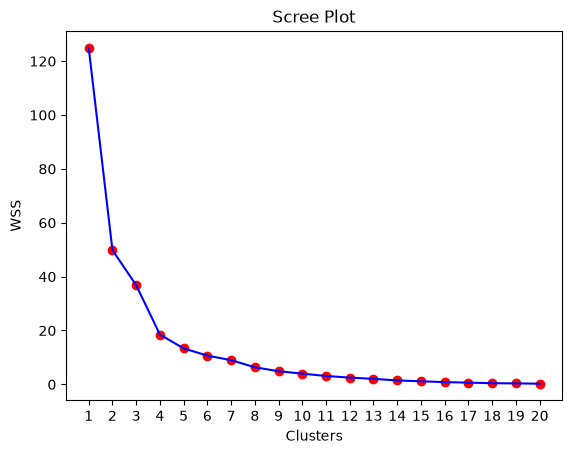

In [64]:
df_wss['K'] = df_wss['K'].astype(str)
plt.scatter(df_wss['K'], df_wss['Score'] , c = 'red')
plt.plot(df_wss['K'], df_wss['Score'] , c = 'blue')
plt.xlabel("Clusters")
plt.ylabel("WSS")
plt.title('Scree Plot')

### By elbow method 4 can be estimate best no of clusters

In [65]:
'''
Why is it called the Elbow Method?

The Goal: You look for an "elbow" or a sharp bend (like a bent arm) in the curve.

The Interpretation: The point where the curve bends represents the optimal number of clusters (K).
Beyond this point, adding more clusters yields diminishing returns in reducing the WSS/inertia.

'''

'\nWhy is it called the Elbow Method?\n\nThe Goal: You look for an "elbow" or a sharp bend (like a bent arm) in the curve.\n\nThe Interpretation: The point where the curve bends represents the optimal number of clusters (K).\nBeyond this point, adding more clusters yields diminishing returns in reducing the WSS/inertia.\n\n'

# Exercise on nutrient

In [69]:
nutrients = pd.read_csv('nutrient.csv',index_col = 0)
nutrients

,energy,protein,fat,calcium,iron
Food_Item,,,,,
BEEF BRAISED,340,20,28,9,2.6
HAMBURGER,245,21,17,9,2.7
BEEF ROAST,420,15,39,7,2.0
BEEF STEAK,375,19,32,9,2.6
BEEF CANNED,180,22,10,17,3.7
CHICKEN BROILED,115,20,3,8,1.4
CHICKEN CANNED,170,25,7,12,1.5
BEEF HEART,160,26,5,14,5.9
LAMB LEG ROAST,265,20,20,9,2.6


In [116]:
scaler = StandardScaler().set_output(transform='pandas')
scl_data = scaler.fit_transform(nutrients)


ks= np.arange(1,21)
wss = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=26)
    km.fit(scl_data)

    wss.append([k, km.inertia_])

wss_df = pd.DataFrame(wss , columns = ['K','Score'])
# wss_df

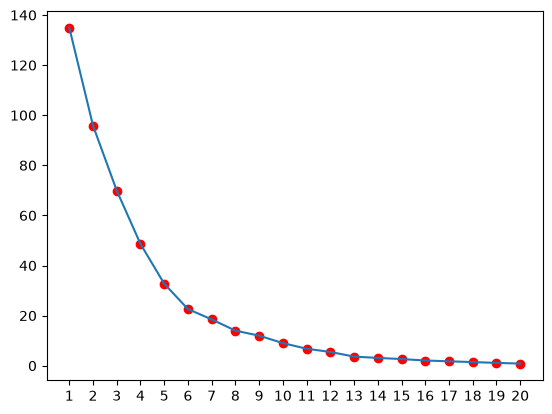

In [117]:
wss_df['K'] = wss_df['K'].astype(str)
plt.scatter(wss_df['K'],wss_df['Score'],c='red')
plt.plot(wss_df['K'],wss_df['Score'])

# Pick the K where the line bends like an elbow (the point of diminishing returns).

In [118]:
km = KMeans(n_clusters=6, random_state=26)
km.fit(scl_data)
# km.inertia_
score = silhouette_score(scl_data, km.labels_)
print("Silhouette Score:", score)

Silhouette Score: 0.3814688639441237


In [119]:
km.labels_

array([0, 2, 0, 0, 2, 2, 2, 4, 0, 0, 0, 0, 0, 2, 2, 2, 3, 3, 1, 1, 2, 1,
       1, 1, 5, 2, 2], dtype=int32)

In [120]:

'''
silhouette_score =  How well-separated and distinct the clusters are from each other.
                    Higher is better (ranges from -1 to +1).
                        
Inertia (WSS) =   How tightly packed the clusters are (distance to centroids).       
                    Lower is better (approaches 0 as k increases).
'''


ks= np.arange(2,21) # for calc silhotte score it requires at least 2 clusters
wss = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=26)
    km.fit(scl_data)
    score = silhouette_score(scl_data, km.labels_)
    wss.append([k , score])

wss_df = pd.DataFrame(wss , columns = ['K' , 'silhouette_score'])
wss_df.sort_values('silhouette_score',ascending=False)

  

,K,silhouette_score
11,13,0.439462
12,14,0.425170
10,12,0.414326
3,5,0.414230
5,7,0.400601
9,11,0.393757
8,10,0.391753
13,15,0.386382
4,6,0.381469
7,9,0.380560
